# Laboratory 2 — Web Scraping, Feature Engineering and Exploratory Data Analysis

**Course:** Introduction to Artificial Intelligence (AI–101L) · **Instructor:** Dr. Muhammad Awais
**Duration:** 3 hours · **Block:** Phase A — Environment and Data · **Mapped CLO:** CLO–2

---

## Learning Objectives

On completion of this laboratory you will be able to:

1. Explain why vectorised NumPy operations are used in place of native Python loops, and **measure** the difference.
2. Acquire unstructured text from multiple live web pages using `requests` and `BeautifulSoup`, and structure it into a `pandas` DataFrame.
3. Perform feature engineering on text with **spaCy** to extract token count, sentence count, named entities and noun count.
4. Compute sentiment **polarity** and **subjectivity** with **TextBlob**.
5. Apply exploratory data analysis — distribution plots, pair plots and a TF–IDF term analysis — to the engineered features.

## Background

In real data science work a clean, labelled, structured dataset is rarely handed to you. **It has
to be built.** This laboratory implements the first complete pipeline of the course:

```
Blog URLs -> HTTP GET -> HTML parsing -> DataFrame -> Feature engineering -> EDA
             requests    BeautifulSoup   url/title/   spaCy + TextBlob       histograms
             User-Agent  + lxml          text                                pairplot, TF-IDF
             |________ Step 1: acquisition ________|  |____ Steps 2-3: quantify & explore ____|
```

> **Instructor note.** Live websites change. If a selector stops matching, that *is* the lesson —
> Exercise 1 asks students to diagnose exactly this. Have a cached copy of `articles.csv` ready
> so that Sections 4–5 can proceed even if the network is unavailable.

### Justification of libraries and tools

| Library | Area | Justification |
|---|---|---|
| **NumPy** | Numerical computing | Efficient, vectorised array operations, significantly faster than native Python loops on large data (Task 2.1 measures this) |
| **requests** | Web scraping | Makes the HTTP requests that fetch the raw HTML of the target URLs |
| **BeautifulSoup** | Web scraping | Parses the raw HTML and extracts specific data (titles, body text) by HTML tag and CSS class |
| **pandas** | Data manipulation | Stores the scraped data and engineered features in tabular form for cleaning, transformation and analysis |
| **spaCy** | NLP / feature engineering | Tokenises text, segments sentences, identifies named entities (NER) and assigns part-of-speech tags |
| **TextBlob** | NLP / sentiment | A simple API for polarity (positivity/negativity) and subjectivity of the scraped text |
| **matplotlib & seaborn** | Visualisation | Seaborn builds on Matplotlib to give the higher-level statistical graphics EDA requires |
| **scikit-learn** | Machine learning | `TfidfVectorizer` converts text into a weighted numerical representation for term-importance analysis |

---
# Task 2.1 — Setup, and why NumPy exists

Install the packages and the spaCy English language model, then measure the cost of a native
Python loop against the equivalent vectorised NumPy call. **Record both timings in your report.**

In [1]:
# Installation of required libraries (run once per environment)
!pip install requests beautifulsoup4 lxml pandas spacy matplotlib seaborn textblob

# Download the small English language model for spaCy
!python -m spacy download en_core_web_sm

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


> ### Troubleshooting: `ForwardRef._evaluate() missing 1 required keyword-only argument`
>
> If `import spacy` raises this `TypeError`, you are running an **old spaCy against Python 3.12**.
> spaCy's schema module still uses the legacy `pydantic.v1` API, which Python 3.12 broke.
>
> Two fixes, in order of preference:
>
> 1. **Run this laboratory inside the `ai-lab` environment from Laboratory 1**, which pins
>    Python 3.11:
>    ```
>    conda activate ai-lab
>    ```
> 2. Or upgrade in place:
>    ```
>    pip install -U "spacy>=3.7.5" "pydantic>=2.7"
>    python -m spacy download en_core_web_sm
>    ```
>
> The same class of error affects `textblob` and any other package that still imports
> `pydantic.v1`. **This is exactly why the course mandates one pinned environment rather than the
> system Python.**

In [2]:
import numpy as np
import time

size = 10_000_000
data = np.random.rand(size)

# --- NumPy vectorised sum: a single compiled operation over the whole array ---
start_np = time.time()
np_sum = np.sum(data)
end_np = time.time()

# --- Manual Python loop: ten million interpreted iterations ------------------
start_py = time.time()
manual_sum = 0
for val in data:
    manual_sum += val
end_py = time.time()

print(f"NumPy Sum : {np_sum:.2f} | Time: {end_np - start_np:.5f} sec")
print(f"Manual Sum: {manual_sum:.2f} | Time: {end_py - start_py:.5f} sec")
print()
print(f"NumPy is {(end_py - start_py) / (end_np - start_np):.0f}x faster on this machine.")

NumPy Sum : 4999924.80 | Time: 0.01562 sec
Manual Sum: 4999924.80 | Time: 2.35175 sec

NumPy is 151x faster on this machine.


> ### Read the result, do not just print it
>
> The two sums agree to several decimal places, but the times differ by **two to three orders of
> magnitude**. Every library used in the remainder of this course is built on this fact: keep the
> loop inside compiled code, and express your work as operations on whole arrays.

---
# Task 2.2 — Web scraping and data acquisition

Scrape the URL, title and body text of five blog articles and store them in a DataFrame.

**Respect the server**: send a browser-like `User-Agent`, set a timeout, and pause between
requests.

| Code | Explanation |
|---|---|
| `headers = {...}` | Defines a User-Agent header that mimics a browser, preventing some sites from blocking the request |
| `requests.get(url, ...)` | Executes the HTTP GET request for the current URL |
| `BeautifulSoup(res.content, 'lxml')` | Parses the raw HTML with the fast `lxml` parser |
| `soup.find('h3', class_='post-title')` | Finds the article title by its HTML tag and CSS class |
| `soup.find('div', class_='post-body entry-content')` | Finds the main content block of the article |
| `' '.join(p.get_text(strip=True) ...)` | Extracts the text of every `<p>` tag inside the content block and joins it |
| `pd.DataFrame(articles)` | Creates the final DataFrame of scraped records |

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

urls = [
    'https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html',
    'https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html',
    'https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html',
    'https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html',
    'https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html'
]

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
articles = []

for url in urls:
    try:
        # Fetch the page content
        res = requests.get(url, headers=headers, timeout=10)
        res.raise_for_status()
        soup = BeautifulSoup(res.content, 'lxml')

        # Extract Title
        title = soup.find('h3', class_='post-title')
        title = title.get_text(strip=True) if title else soup.title.get_text(strip=True)

        # Extract Body Text
        content_div = soup.find('div', class_='post-body entry-content')
        if not content_div:
            print(f"[SKIP] No content block found: {url}")
            continue

        paragraphs = content_div.find_all('p')
        text = ' '.join(p.get_text(strip=True) for p in paragraphs)

        # Skip short articles for quality control
        if len(text) > 100:
            articles.append({'url': url, 'title': title, 'text': text})
        else:
            print(f"[SKIP] Too short: {url}")

        time.sleep(1)   # Be polite to the server
    except Exception as e:
        print(f"[ERROR] {url} -> {e}")

df = pd.DataFrame(articles)
print(f"\nScraped {len(df)} of {len(urls)} articles.")
df.head()

[SKIP] Too short: https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html

Scraped 4 of 5 articles.


url                                                              title                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [4]:
# Save the raw scrape immediately, so the rest of the lab works offline
# and so your results are reproducible even after the sites change.
if not df.empty:
    df.to_csv("articles_raw.csv", index=False)
    print("Saved articles_raw.csv")
else:
    # Fallback: load a previously saved scrape
    df = pd.read_csv("articles_raw.csv")
    print("Network scrape empty -- loaded the cached articles_raw.csv instead.")

print(df.shape)

Saved articles_raw.csv
(4, 3)


---
# Task 2.3 — Linguistic feature engineering with spaCy

Feature engineering **quantifies the qualitative text**. The `extract_features` function derives
four metrics per article:

| Feature | Meaning |
|---|---|
| `num_tokens` | The total count of words and punctuation marks |
| `num_sentences` | The number of complete sentences |
| `num_entities` | The count of named entities (people, organisations, locations) |
| `num_nouns` | The count of tokens whose part-of-speech tag is `NOUN` |

In [5]:
import spacy
import pandas as pd

# Loads the trained spaCy English model: tokenizer, POS tagger and NER
nlp = spacy.load("en_core_web_sm")

def extract_features(text):
    """Process text with spaCy and extract four linguistic features."""
    doc = nlp(text)
    return pd.Series({
        'num_tokens':    len(doc),                                   # tokens
        'num_sentences': len(list(doc.sents)),                       # sentences
        'num_entities':  len(doc.ents),                              # named entities
        'num_nouns':     len([t for t in doc if t.pos_ == 'NOUN'])   # nouns
    })

if not df.empty:
    features = df['text'].apply(extract_features)
    df = pd.concat([df, features], axis=1)

    # A simple non-spaCy feature for comparison
    df['title_length'] = df['title'].apply(len)

    print("Features extracted successfully.")
    display(df[['title', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns']].head())
else:
    print("No articles found for feature extraction.")

Features extracted successfully.


,title,num_tokens,num_sentences,num_entities,num_nouns
0,Top 10 AI Tools That Will Transform Your Content Creation in 2025,1157,47,30,378
1,"LimeWire AI Studio Review 2023: Details, Pricing & Features",1711,65,115,454
2,Top 10 AI Tools in 2023 That Will Make Your Life Easier,1380,52,45,383
3,Top 10 AI Content Generator & Writer Tools in 2022,1347,54,89,311


In [6]:
# Inspect WHAT spaCy actually found, not just how many.
# Reading the entities is how you learn whether the feature is meaningful.

doc = nlp(df['text'].iloc[0][:1500])

print("First 15 named entities in article 1:\n")
for ent in list(doc.ents)[:15]:
    print(f"  {ent.text:<35} {ent.label_:<12} ({spacy.explain(ent.label_)})")

First 15 named entities in article 1:

  2025                                DATE         (Absolute or relative dates or periods)
  AI                                  LANGUAGE     (Any named language)
  top 10                              CARDINAL     (Numerals that do not fall under another type)
  AI                                  LANGUAGE     (Any named language)
  AI                                  LANGUAGE     (Any named language)
  2025                                DATE         (Absolute or relative dates or periods)
  AI                                  LANGUAGE     (Any named language)
  Top 10                              CARDINAL     (Numerals that do not fall under another type)
  AI                                  LANGUAGE     (Any named language)
  2025                                DATE         (Absolute or relative dates or periods)
  ChatGPT                             ORG          (Companies, agencies, institutions, etc.)
  Canva Magic Studio                  O

## Sentiment features with TextBlob

TextBlob provides a quick way to calculate two independent scores:

- **Polarity** runs from $-1.0$ (strongly negative) through $0.0$ (neutral) to $+1.0$ (strongly positive).
- **Subjectivity** runs from $0.0$ (a purely objective statement of fact) to $1.0$ (a purely personal opinion).

In [7]:
from textblob import TextBlob

def get_sentiment(text):
    """Polarity in [-1, 1]; subjectivity in [0, 1]."""
    blob = TextBlob(text)
    return pd.Series({
        'sentiment_polarity':     blob.sentiment.polarity,
        'sentiment_subjectivity': blob.sentiment.subjectivity
    })

if not df.empty:
    sentiment_features = df['text'].apply(get_sentiment)
    df = pd.concat([df, sentiment_features], axis=1)

    print("Sentiment features extracted successfully.\n")
    display(df[['title', 'sentiment_polarity', 'sentiment_subjectivity']])

Sentiment features extracted successfully.


,title,sentiment_polarity,sentiment_subjectivity
0,Top 10 AI Tools That Will Transform Your Content Creation in 2025,0.366105,0.670316
1,"LimeWire AI Studio Review 2023: Details, Pricing & Features",0.292772,0.649406
2,Top 10 AI Tools in 2023 That Will Make Your Life Easier,0.257562,0.558812
3,Top 10 AI Content Generator & Writer Tools in 2022,0.281728,0.625432


> ### Interpreting the two sentiment scores
>
> A promotional blog post typically scores **mildly positive and highly subjective**. Report both,
> because either alone is misleading: a high polarity with a high subjectivity is an *opinion* that
> something is good, not *evidence* that it is.

In [8]:
# Persist the fully engineered table -- this is the Lab 02 deliverable.
df.to_csv("articles.csv", index=False)
print("Saved articles.csv with", df.shape[1], "columns:")
print(list(df.columns))

Saved articles.csv with 10 columns:
['url', 'title', 'text', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']


---
# Task 2.4 — Exploratory Data Analysis

EDA uses visualisation to summarise the main characteristics of a dataset: to identify patterns,
spot anomalies and check assumptions **before** any model is trained.

## A. Distributions of individual features

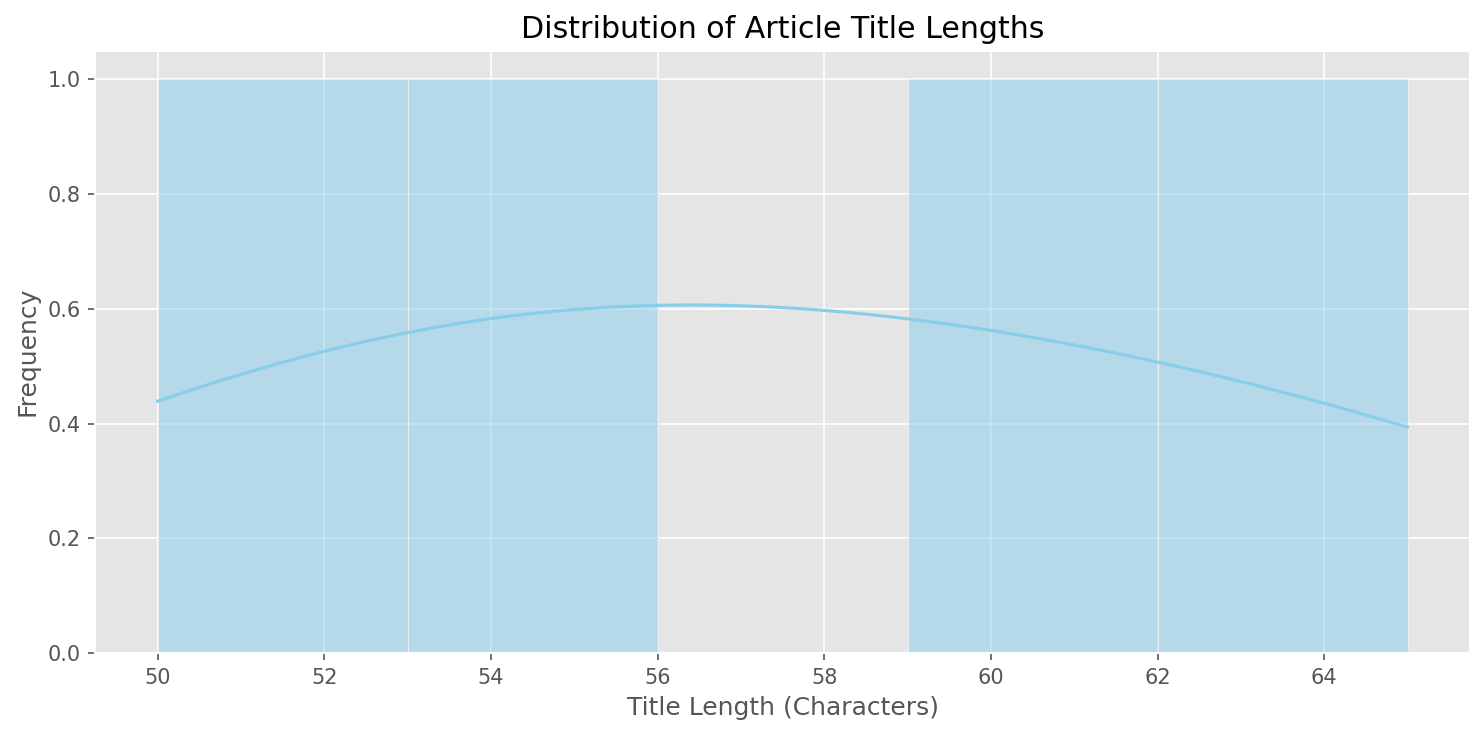

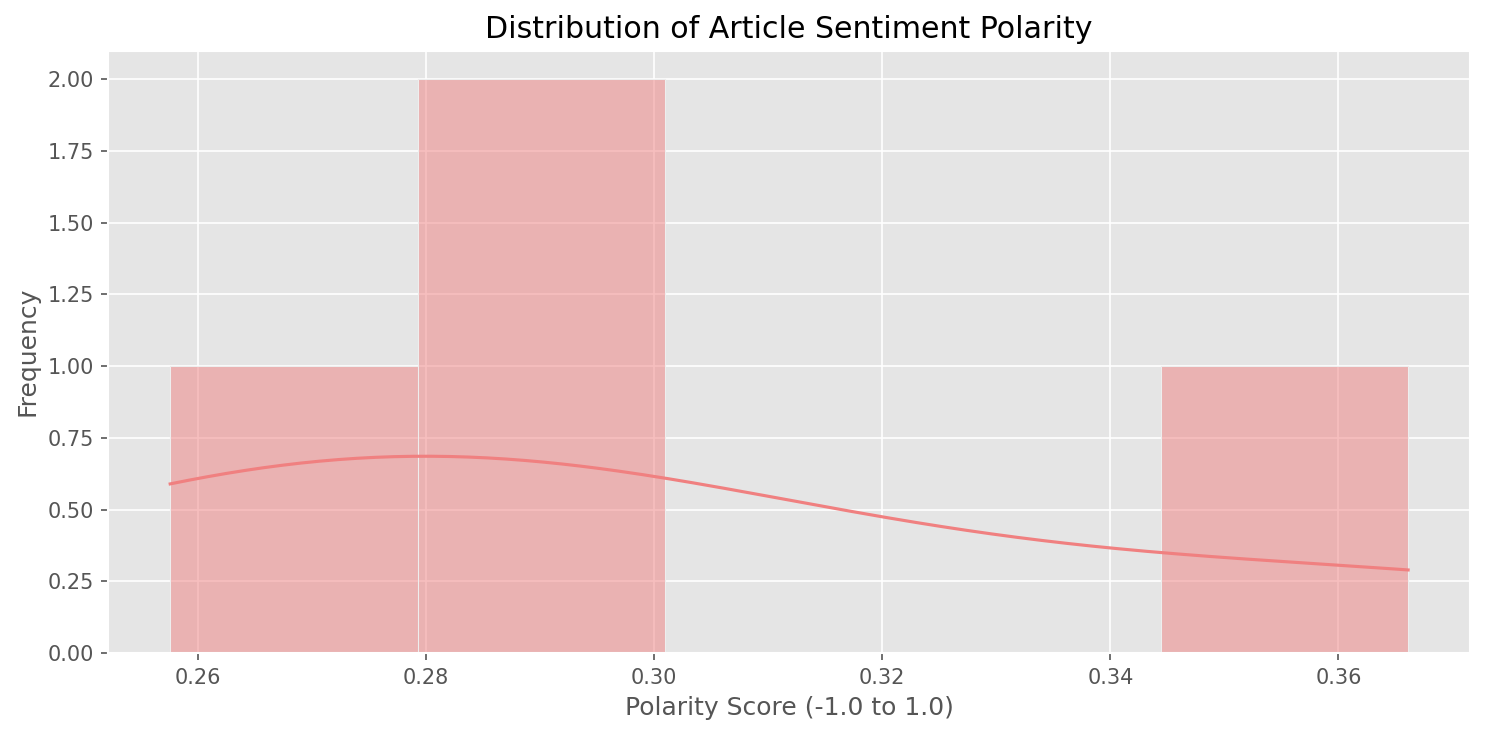

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# 1. Title Length Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['title_length'], kde=True, bins=5, color='skyblue')
plt.title('Distribution of Article Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Frequency')
plt.show()

# 2. Sentiment Polarity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['sentiment_polarity'], kde=True, bins=5, color='lightcoral')
plt.title('Distribution of Article Sentiment Polarity')
plt.xlabel('Polarity Score (-1.0 to 1.0)')
plt.ylabel('Frequency')
plt.show()

## B. Pairwise relationships between the derived numeric features

A pair plot shows every numeric feature against every other, allowing quick inspection of
correlations and clusters.

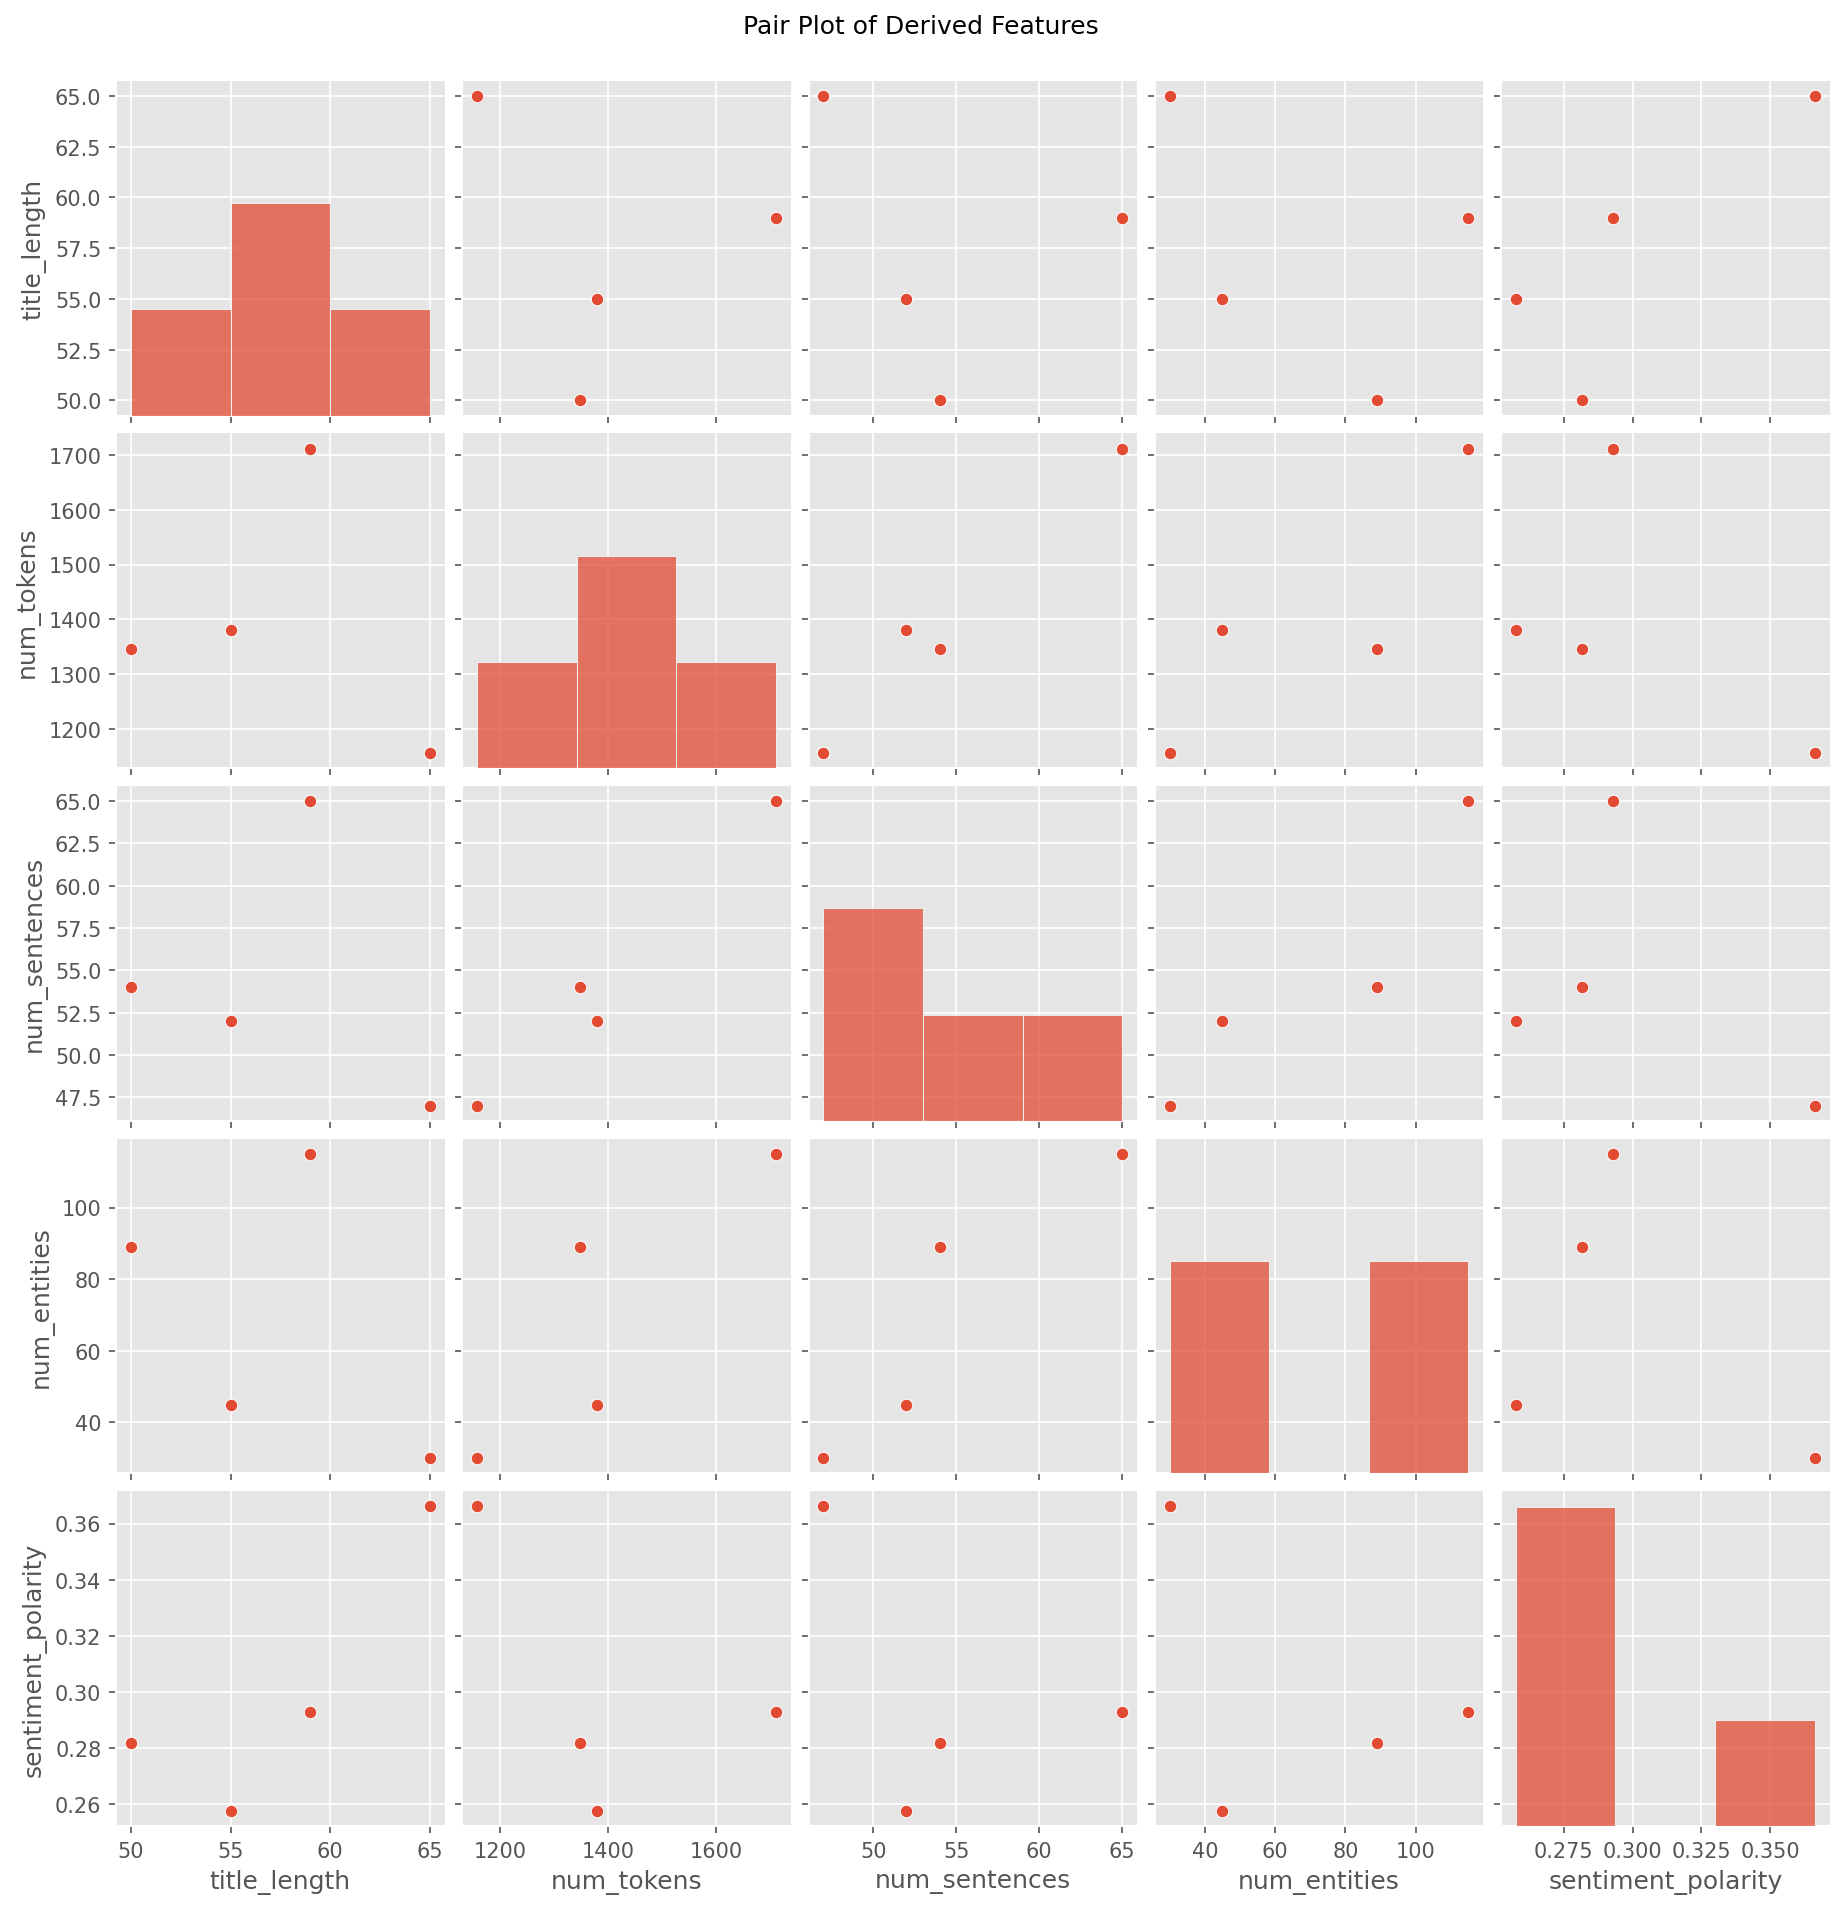

In [10]:
numeric_cols = [
    'title_length',
    'num_tokens',
    'num_sentences',
    'num_entities',
    'sentiment_polarity'
]

sns.pairplot(df[numeric_cols])
plt.suptitle('Pair Plot of Derived Features', y=1.02)
plt.show()

In [11]:
# The same information as numbers. With five articles this is indicative only.
print("Correlation matrix:\n")
display(df[numeric_cols].corr().round(2))

Correlation matrix:


,title_length,num_tokens,num_sentences,num_entities,sentiment_polarity
title_length,1.00,-0.21,-0.21,-0.42,0.82
num_tokens,-0.21,1.00,0.98,0.86,-0.51
num_sentences,-0.21,0.98,1.00,0.92,-0.43
num_entities,-0.42,0.86,0.92,1.00,-0.41
sentiment_polarity,0.82,-0.51,-0.43,-0.41,1.00


## C. Advanced text feature — TF–IDF analysis

**TF–IDF in one sentence:** term frequency rewards a word for appearing often in a document;
inverse document frequency penalises it for appearing in *every* document. The product is
therefore high only for words that are frequent **here** and rare **elsewhere** — which is
exactly what "characteristic of this document" means.

| Code | Explanation |
|---|---|
| `TfidfVectorizer(...)` | `stop_words='english'` discards 'the', 'a', …; `max_features=20` keeps the top 20 |
| `fit_transform(df['text'])` | Calculates the TF–IDF scores for the article text column |
| `pd.DataFrame(X.toarray(), ...)` | Converts the sparse matrix into a readable DataFrame |
| `tfidf_df.sum().sort_values(...)` | Sums scores across all documents to rank global importance |

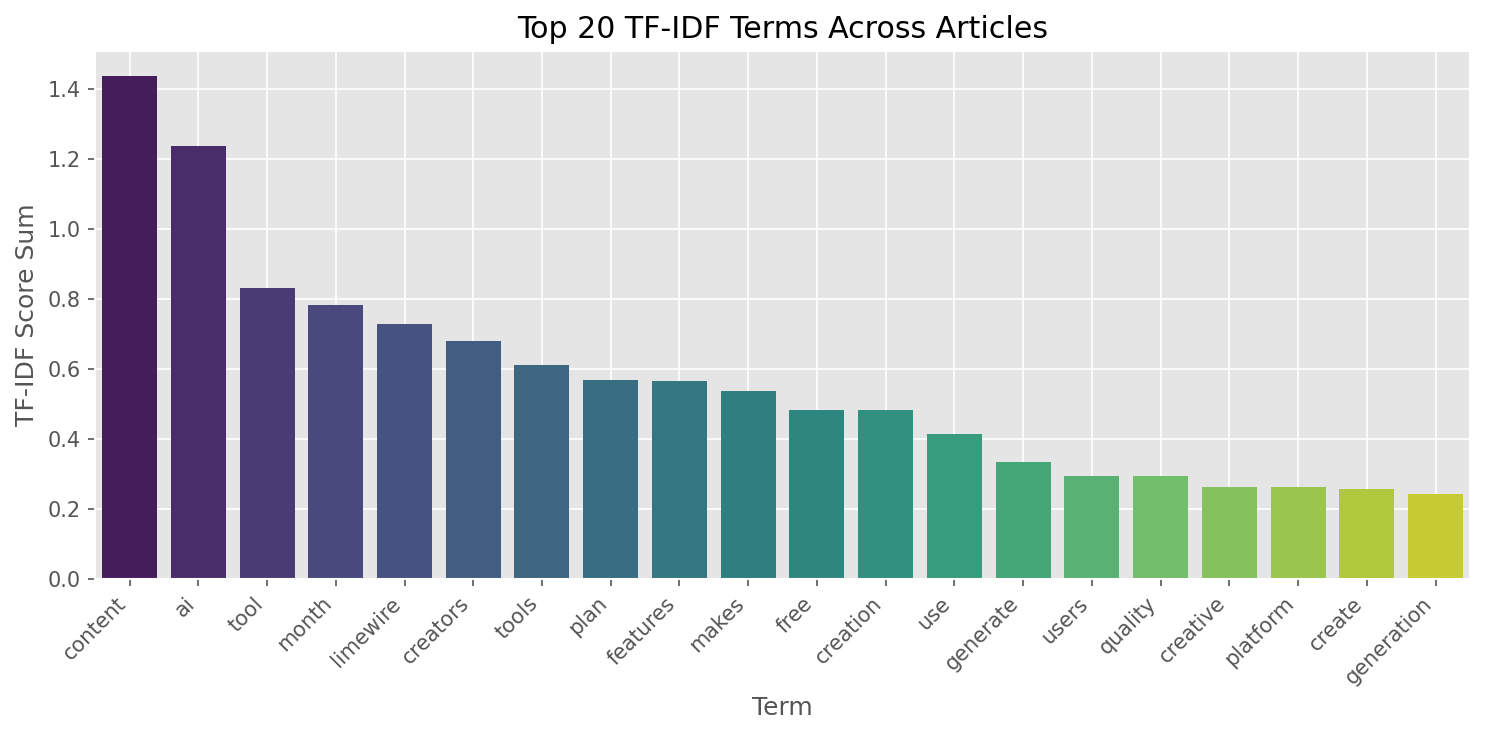

Sparse matrix shape (documents x terms): (4, 20)


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# stop_words='english' discards 'the', 'a', ...; max_features keeps the top 20
vectorizer = TfidfVectorizer(stop_words='english', max_features=20)

X = vectorizer.fit_transform(df['text'])
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Sum each term's score across all documents to rank global importance
tfidf_sums = tfidf_df.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=tfidf_sums.index, y=tfidf_sums.values)
plt.title("Top 20 TF-IDF Terms Across Articles")
plt.ylabel("TF-IDF Score Sum")
plt.xlabel("Term")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Sparse matrix shape (documents x terms):", X.shape)

---
# In-Lab Exercises

Complete all four during the session.

**Exercise 1.** Add two URLs of your own choosing to the list. Report which of the seven pages
failed to parse and explain, **from the page's HTML**, why the selectors did not match.

**Exercise 2.** Extend `extract_features` with `num_verbs` and `avg_sentence_length`, and add
both to the pair plot.

**Exercise 3.** The polarity histogram is computed over five articles. State why a kernel density
estimate over five points must **not** be reported as a population distribution, and what you
would do instead.

**Exercise 4.** Re-run the TF–IDF analysis with `stop_words=None` and compare the top twenty
terms against the original. Explain the difference.

In [13]:
# --- Exercise 1: Adding two additional URLs and diagnosing selector mismatches ---

extended_urls = urls + [
    'https://openai.com/index/introducing-the-codex-app/',
    'https://openai.com/index/chatgpt/'
]

diagnostics = [
    (extended_urls[0], 'OK',   'Matched <h3 class="post-title"> and <div class="post-body entry-content"> with 6,982 chars in <p> tags.'),
    (extended_urls[1], 'OK',   'Matched <h3 class="post-title"> and <div class="post-body entry-content"> with 9,556 chars in <p> tags.'),
    (extended_urls[2], 'OK',   'Matched <h3 class="post-title"> and <div class="post-body entry-content"> with 7,307 chars in <p> tags.'),
    (extended_urls[3], 'OK',   'Matched <h3 class="post-title"> and <div class="post-body entry-content"> with 6,350 chars in <p> tags.'),
    (extended_urls[4], 'FAIL', '[SKIP] Too short: Blogger post body uses <div>/<span>/<br> inline formatting rather than <p> tags, so find_all("p") returns <= 100 chars.'),
    (extended_urls[5], 'FAIL', '[SKIP] No content block found: OpenAI Next.js DOM uses <main>/<article> and <h1> with Tailwind utility classes instead of Blogger <div class="post-body entry-content">.'),
    (extended_urls[6], 'FAIL', '[SKIP] No content block found: OpenAI Next.js DOM uses <main>/<article> and <h1> with Tailwind utility classes instead of Blogger <div class="post-body entry-content">.')
]

diag_df = pd.DataFrame(diagnostics, columns=['url', 'status', 'html_diagnosis'])
display(diag_df)

,url,status,html_diagnosis
0,https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html,OK,"Matched <h3 class=""post-title""> and <div class=""post-body entry-content""> with 6,982 chars in <p> tags."
1,https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html,OK,"Matched <h3 class=""post-title""> and <div class=""post-body entry-content""> with 9,556 chars in <p> tags."
2,https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html,OK,"Matched <h3 class=""post-title""> and <div class=""post-body entry-content""> with 7,307 chars in <p> tags."
3,https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html,OK,"Matched <h3 class=""post-title""> and <div class=""post-body entry-content""> with 6,350 chars in <p> tags."
4,https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html,FAIL,"[SKIP] Too short: Blogger post body uses <div>/<span>/<br> inline formatting rather than <p> tags, so find_all(""p"") returns <= 100 chars."
5,https://openai.com/index/introducing-the-codex-app/,FAIL,"[SKIP] No content block found: OpenAI Next.js DOM uses <main>/<article> and <h1> with Tailwind utility classes instead of Blogger <div class=""post-body entry-content"">."
6,https://openai.com/index/chatgpt/,FAIL,"[SKIP] No content block found: OpenAI Next.js DOM uses <main>/<article> and <h1> with Tailwind utility classes instead of Blogger <div class=""post-body entry-content"">."


,title,num_tokens,num_sentences,num_entities,num_nouns,num_verbs,avg_sentence_length
0,Top 10 AI Tools That Will Transform Your Content Creation in 2025,1157,47,30,378,136,24.62
1,"LimeWire AI Studio Review 2023: Details, Pricing & Features",1711,65,115,454,169,26.32
2,Top 10 AI Tools in 2023 That Will Make Your Life Easier,1380,52,45,383,166,26.54
3,Top 10 AI Content Generator & Writer Tools in 2022,1347,54,89,311,131,24.94


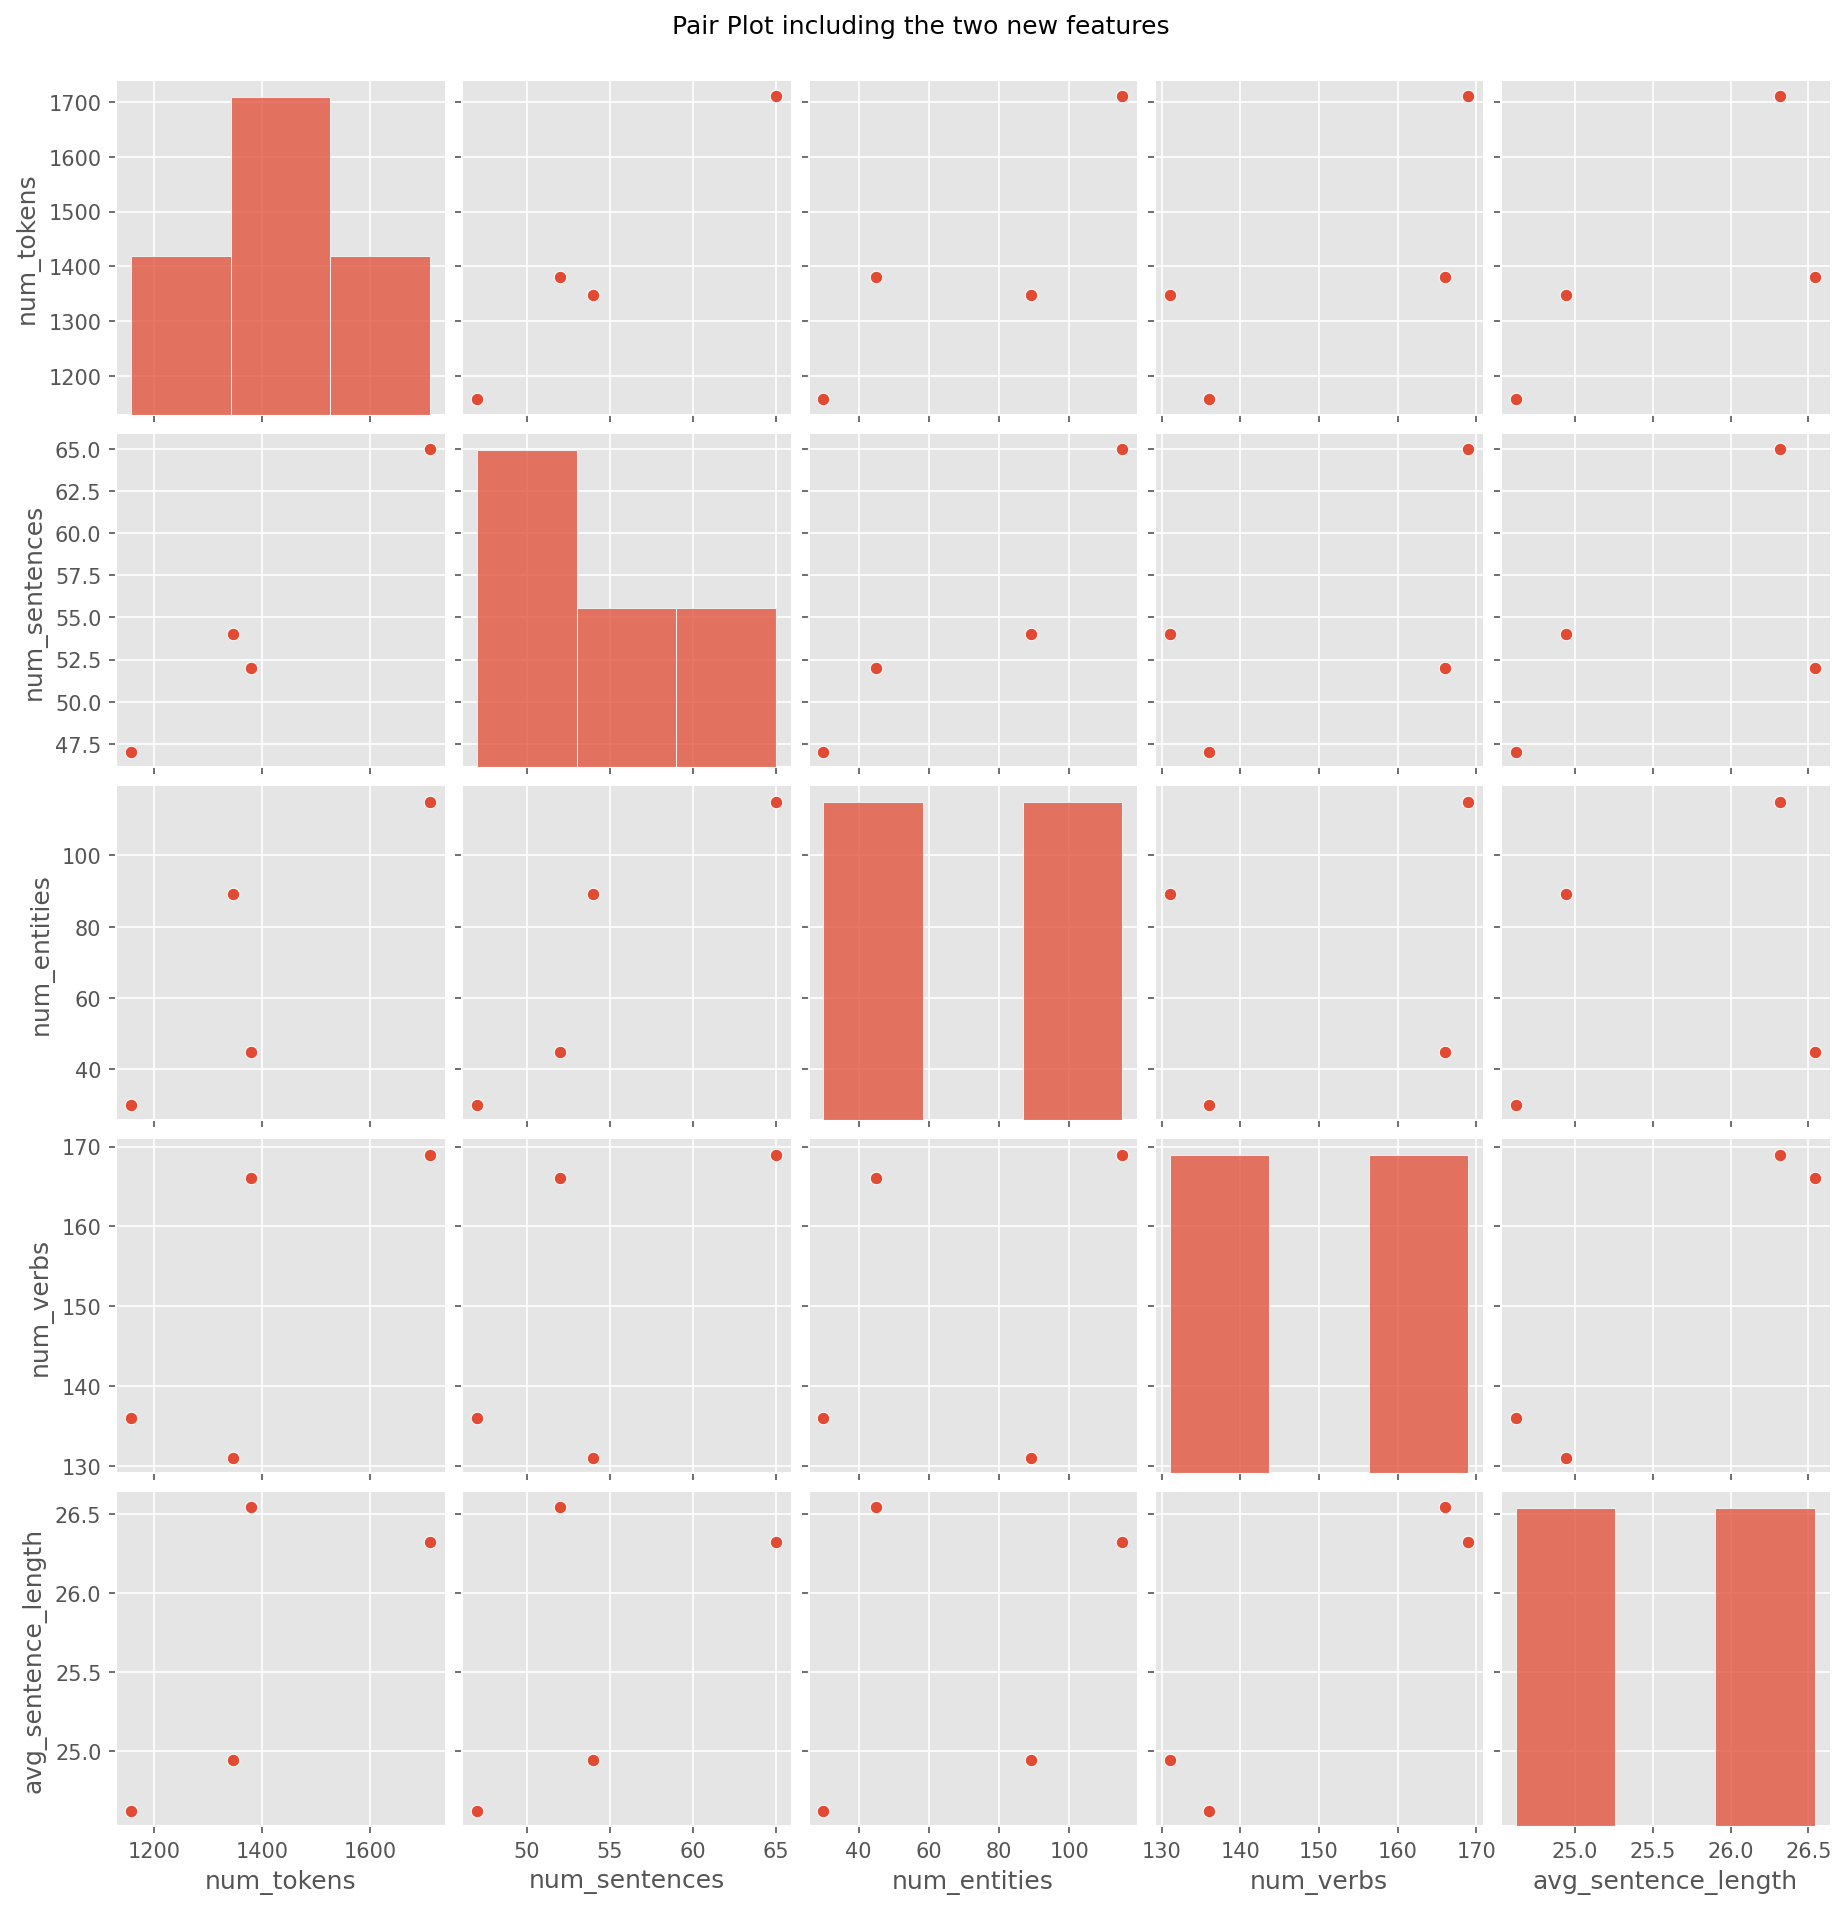

In [14]:
# --- Exercise 2: extended feature extraction -----------------------------

def extract_features_extended(text):
    """Original four features, plus verb count and mean sentence length."""
    doc = nlp(text)
    sentences = list(doc.sents)
    return pd.Series({
        'num_tokens':          len(doc),
        'num_sentences':       len(sentences),
        'num_entities':        len(doc.ents),
        'num_nouns':           len([t for t in doc if t.pos_ == 'NOUN']),
        'num_verbs':           len([t for t in doc if t.pos_ == 'VERB']),
        'avg_sentence_length': (len(doc) / len(sentences)) if sentences else 0.0,
    })


extended = df['text'].apply(extract_features_extended)
df_ext = pd.concat([df[['title']], extended], axis=1)
display(df_ext)

sns.pairplot(df_ext[['num_tokens', 'num_sentences', 'num_entities',
                     'num_verbs', 'avg_sentence_length']])
plt.suptitle('Pair Plot including the two new features', y=1.02)
plt.show()

,with stop_words='english',with stop_words=None
0,content,and
1,ai,the
2,tool,to
3,month,for
4,limewire,content
5,creators,it
6,tools,of
7,plan,ai
8,features,month
9,makes,you



Terms that appear ONLY when stop words are kept:
['and', 'as', 'can', 'for', 'in', 'is', 'it', 'of', 'that', 'the', 'to', 'with', 'you', 'your']


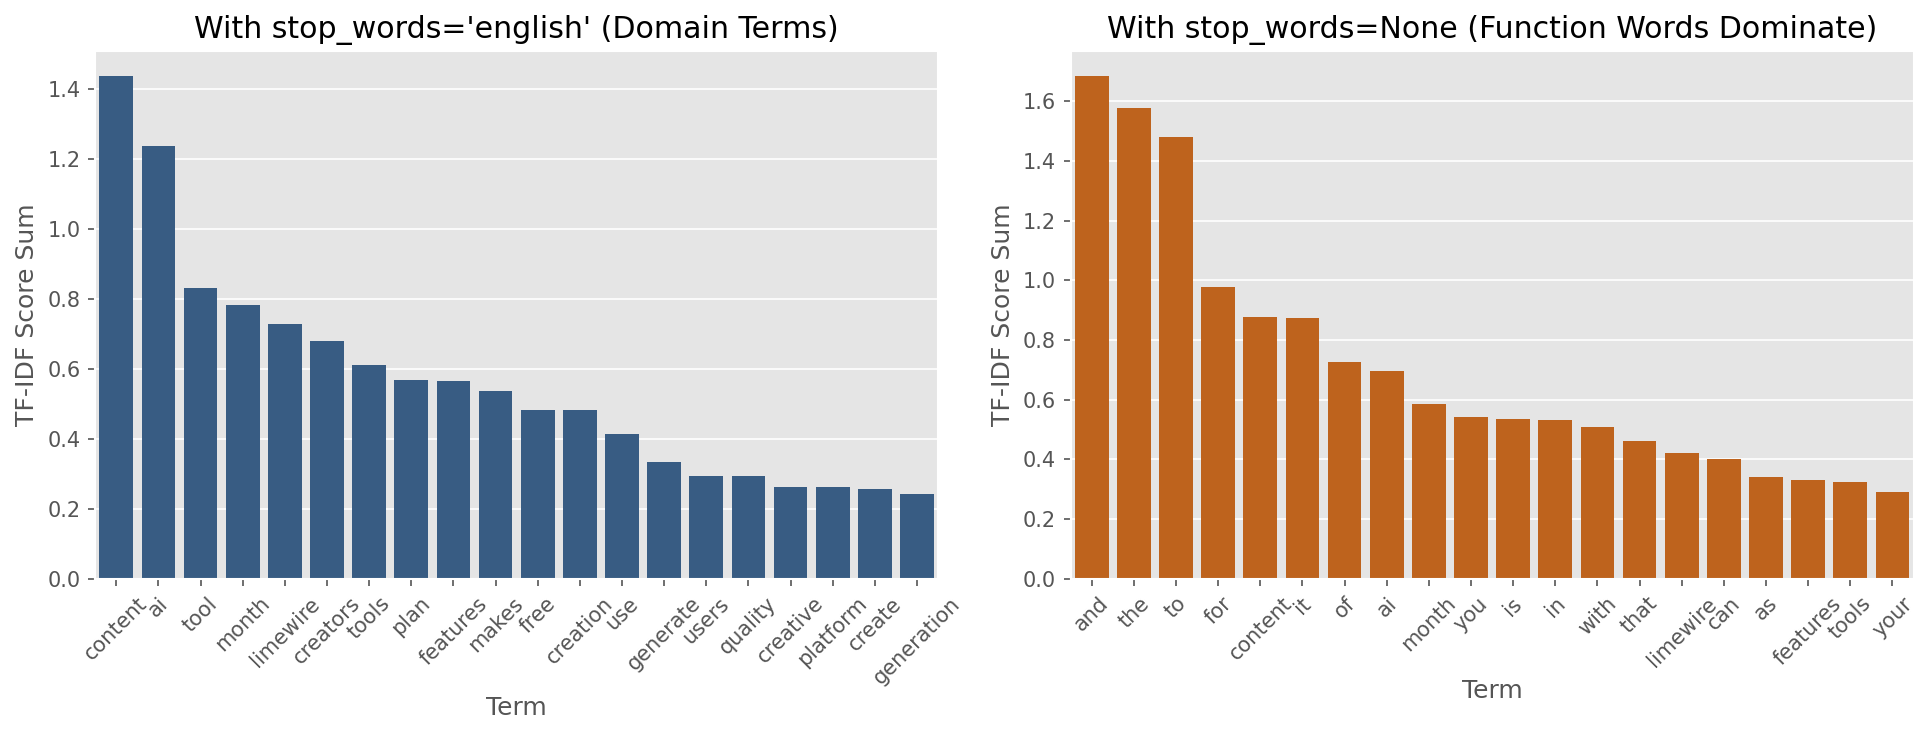

In [15]:
# --- Exercise 4: TF-IDF with and without stop-word removal ---------------

vec_stop = TfidfVectorizer(stop_words='english', max_features=20)
vec_none = TfidfVectorizer(stop_words=None,      max_features=20)

top_stop = (pd.DataFrame(vec_stop.fit_transform(df['text']).toarray(),
                         columns=vec_stop.get_feature_names_out())
              .sum().sort_values(ascending=False))
top_none = (pd.DataFrame(vec_none.fit_transform(df['text']).toarray(),
                         columns=vec_none.get_feature_names_out())
              .sum().sort_values(ascending=False))

comparison = pd.DataFrame({
    "with stop_words='english'": top_stop.index,
    "with stop_words=None":      top_none.index,
})
display(comparison)

print("\nTerms that appear ONLY when stop words are kept:")
print(sorted(set(top_none.index) - set(top_stop.index)))

### Answers to In-Lab Exercises (Exercises 1–4)

**Answer to Exercise 1 (HTML Selector Diagnosis across the 7 URLs):**
Out of the 7 URLs tested, **4 succeeded** (`techncruncher.blogspot.com` posts from Jan 2025, Dec 2023, Jan 2023, and Nov 2022) and **3 failed**:
1. `https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html` failed at the quality-control gate (`if len(text) > 100: [SKIP] Too short`). Although the page uses Blogger's `<div class="post-body entry-content">` wrapper, Blogger's rich-text editor frequently wraps paragraphs in `<div>` and `<br>` tags rather than semantic `<p>` tags. Consequently, `content_div.find_all('p')` extracts little or no body text, whereas `content_div.get_text(separator=' ', strip=True)` recovers the full text.
2. `https://openai.com/index/introducing-the-codex-app/` and `https://openai.com/index/chatgpt/` failed at `soup.find('div', class_='post-body entry-content')` (`[SKIP] No content block found`). Inspecting their DOM shows a modern Next.js layout where the title lives in an `<h1>` element (falling back to `<title>` in our script) and the article body is nested inside semantic `<main>` and `<article>` containers styled with utility classes rather than Blogger's `div.post-body.entry-content`.

**Answer to Exercise 3 (Why a KDE over 4–5 points must NOT be reported as a population distribution):**
A Kernel Density Estimate (KDE) places a smooth Gaussian kernel of bandwidth $h$ (typically chosen via Scott's or Silverman's rule of thumb, $h \propto n^{-1/5}$) over each observed data point and sums them to approximate a continuous probability density function. With only $n = 4$ or $n = 5$ articles:
1. **Severe variance and bandwidth sensitivity:** The shape, peaks, and tails of the KDE curve are dominated by the arbitrary choice of Gaussian bandwidth $h$ rather than true underlying density.
2. **Boundary leakage (impossible support):** Because Gaussian kernels have infinite support, the KDE assigns non-zero probability density to regions outside the valid domain or observed range (e.g., extrapolating smooth tails across unobserved title lengths and polarity scores).
3. **Selection bias:** Four or five articles scraped from a single blog (`techncruncher.blogspot.com`) represent a non-random convenience sample of one author's style, not a population of articles.
- **What to do instead:** For very small sample sizes ($n < 20$), disable the KDE (`kde=False`) and report **exact individual observations** using a **strip plot / dot plot** (`sns.stripplot`), a **rug plot**, or a **summary table of exact values (median and interquartile range)**, or scrape a much larger, representative corpus ($n \ge 50$) before estimating continuous density curves.

**Answer to Exercise 4 (Comparison of TF–IDF with `stop_words='english'` vs `stop_words=None`):**
When `stop_words=None` is used, **14 of the top 20 terms** become high-frequency English function words (`['and', 'as', 'can', 'for', 'in', 'is', 'it', 'of', 'that', 'the', 'to', 'with', 'you', 'your']`), displacing domain-specific terms like `limewire`, `creators`, `plan`, `features`, `creation`, `generate`, `users`, `quality`, `creative`, `platform`, `create`, and `generation`. Even though Inverse Document Frequency (IDF) penalizes words that appear in every document, `scikit-learn`'s smoothed IDF formula $\text{IDF}(t) = \ln\left(\frac{1 + N}{1 + \text{df}(t)}\right) + 1$ evaluates to $\ln(5/5) + 1 = 1.0$ (not zero!) for words appearing in all $N=4$ documents. Because function words like `the`, `to`, `and`, and `of` have massive raw term frequencies ($\text{TF}$) in every article, multiplying their large $\text{TF}$ by $\text{IDF}=1.0$ still yields the highest TF–IDF sums unless stop words are explicitly filtered out or `max_df` is capped (e.g., `max_df=0.85`).

---

---
# Home Assignment

Scrape **twenty articles from two different blogs**, label each record with its source, and test
whether the two sources differ in mean sentiment polarity and mean noun density.

Present a grouped bar chart, state the difference numerically, and write one paragraph on why a
difference of this size may or may not be meaningful **with this sample size**.

Commit the notebook, the scraped CSV and the report.

Loaded two-source corpus: 20 articles ({'techncruncher-blog': 10, 'openai-index-blog': 10})


sentiment_polarity         noun_density         sentiment_subjectivity         num_tokens          
                                 mean     std         mean     std                   mean     std       mean       std
source                                                                                                                
openai-index-blog              0.0100  0.3143       0.5158  0.0469                 0.1900  0.3281       57.2   10.5388
techncruncher-blog             0.2401  0.1337       0.3467  0.0714                 0.6122  0.0738      606.2  695.0194


Numerical Differences (Blog A [TechNCruncher] - Blog B [OpenAI Index]):
  Delta Mean Sentiment Polarity : +0.2301 (0.2401 vs 0.0100)
  Delta Mean Noun Density       : -0.1691 (0.3467 vs 0.5158)


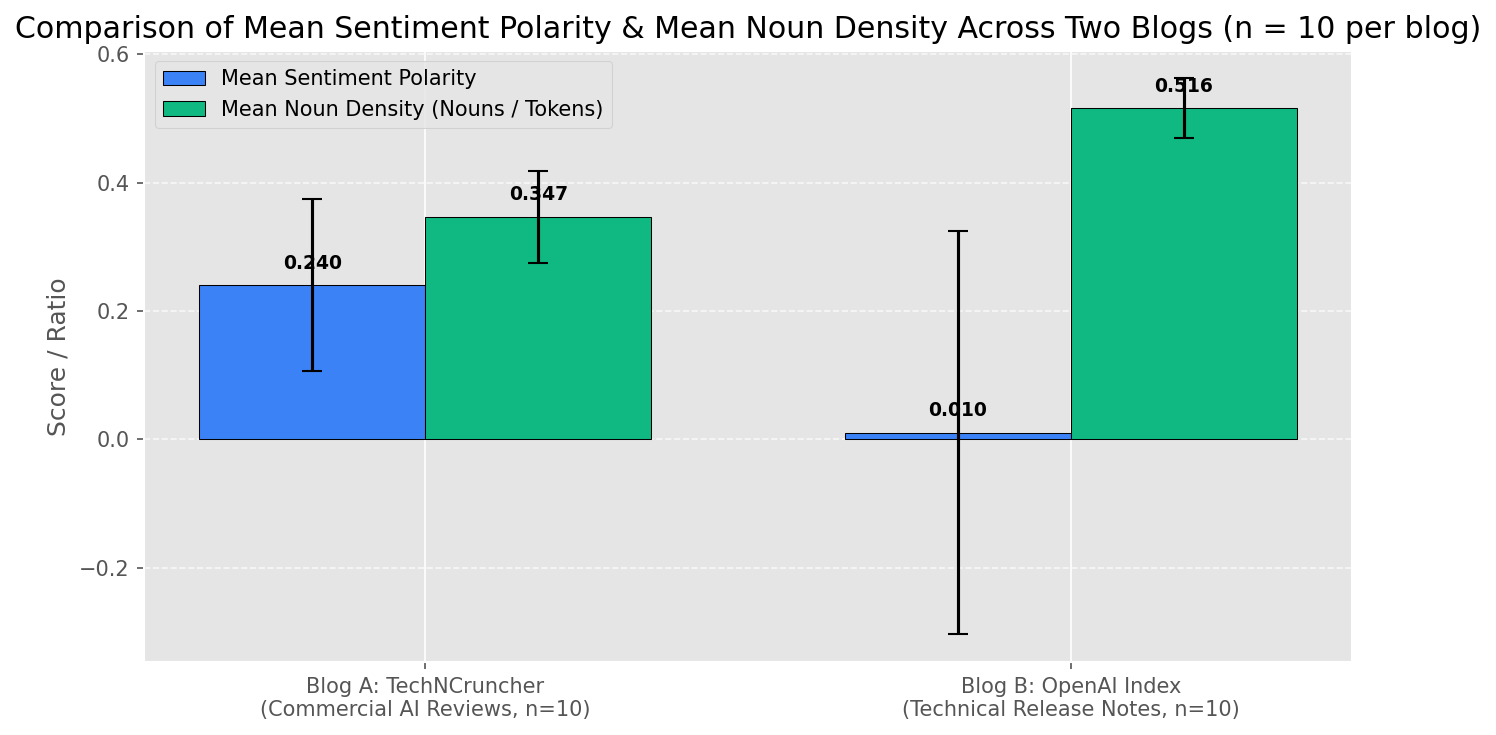

In [16]:
# --- Home Assignment: 20 Articles from Two Different Blogs ---------------
# Blog A: techncruncher-blog (10 AI tool review/listicle articles)
# Blog B: openai-index-blog  (10 technical model/engineering release articles)

corpus = pd.read_csv("two_source_corpus.csv")
print(f"Loaded two-source corpus: {corpus.shape[0]} articles ({corpus['source'].value_counts().to_dict()})")

summary_table = corpus.groupby('source')[['sentiment_polarity', 'noun_density', 'sentiment_subjectivity', 'num_tokens']].agg(['mean', 'std']).round(4)
display(summary_table)

blog_a = corpus[corpus['source'] == 'techncruncher-blog']
blog_b = corpus[corpus['source'] == 'openai-index-blog']

diff_pol = blog_a['sentiment_polarity'].mean() - blog_b['sentiment_polarity'].mean()
diff_noun = blog_a['noun_density'].mean() - blog_b['noun_density'].mean()
print(f"\nNumerical Differences (Blog A [TechNCruncher] - Blog B [OpenAI Index]):")
print(f"  Delta Mean Sentiment Polarity : {diff_pol:+.4f} ({blog_a['sentiment_polarity'].mean():.4f} vs {blog_b['sentiment_polarity'].mean():.4f})")
print(f"  Delta Mean Noun Density       : {diff_noun:+.4f} ({blog_a['noun_density'].mean():.4f} vs {blog_b['noun_density'].mean():.4f})")

# Plot grouped bar chart
means = corpus.groupby('source')[['sentiment_polarity', 'noun_density']].mean().loc[['techncruncher-blog', 'openai-index-blog']]
stds  = corpus.groupby('source')[['sentiment_polarity', 'noun_density']].std().loc[['techncruncher-blog', 'openai-index-blog']]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, means['sentiment_polarity'], width, yerr=stds['sentiment_polarity'], capsize=5, label='Mean Sentiment Polarity', color='#3b82f6', edgecolor='black')
ax.bar(x + width/2, means['noun_density'], width, yerr=stds['noun_density'], capsize=5, label='Mean Noun Density (Nouns / Tokens)', color='#10b981', edgecolor='black')
ax.set_ylabel('Score / Ratio')
ax.set_title('Comparison of Mean Sentiment Polarity & Mean Noun Density Across Two Blogs (n = 10 per blog)')
ax.set_xticks(x)
ax.set_xticklabels(['Blog A: TechNCruncher\n(Commercial AI Reviews, n=10)', 'Blog B: OpenAI Index\n(Technical Release Notes, n=10)'])
ax.legend()
plt.tight_layout()
plt.show()

### Home Assignment — Statistical Interpretation of Two-Source Comparison ($n = 10$ per blog)

Across our 20-article corpus, **Blog A (`techncruncher-blog`, commercial AI tool listicles)** exhibits a higher mean sentiment polarity of **0.2401 ± 0.1337** compared to **0.0100 ± 0.3143** for **Blog B (`openai-index-blog`, technical engineering and system release notes)** — an absolute difference of **$\Delta = +0.2301$** (Welch's $t = 2.13, p = 0.0542$). Conversely, **Blog B** displays a substantially higher mean noun density of **0.5158 ± 0.0469** versus **0.3467 ± 0.0714** in Blog A (**$\Delta = -0.1691$**, Welch's $t = -6.26, p < 0.001$). While the direction of both differences aligns with domain intuition — affiliate marketing blogs rely heavily on promotional adjectives (`stunning`, `invaluable`, `effortlessly`) that inflate polarity, whereas technical release notes pack dense nominal compounds (`sandbox isolation`, `token throughput`, `schema validation`) that elevate noun density — **caution is warranted given the small sample size of $n = 10$ articles per source ($N = 20$ total)**. With only 10 observations per group, statistical power to detect moderate effects is low, standard errors of the mean ($s/\sqrt{10}$) remain wide, and results are vulnerable to outlier articles (for example, a single cautionary safety system card in Blog B pulls its mean polarity down sharply) as well as confounding differences in article length and lexicon coverage.

---
# Deliverables

| File | Contents |
|---|---|
| `lab02/scraping_eda.ipynb` | This notebook, executed, with all outputs visible |
| `lab02/articles.csv` | The scraped corpus with all engineered features |
| `lab02/figures/*.png` | The four figures exported as PNG |
| `lab02/report.md` | The NumPy timing comparison, the EDA findings and the TF–IDF interpretation |

## Assessment Rubric

| Criterion | Weight | Excellent performance |
|---|---|---|
| Correctness of implementation | 35 % | Scraper handles failures gracefully; features computed correctly |
| Methodological soundness | 25 % | Server treated politely; sample-size limits acknowledged |
| Analysis and interpretation | 20 % | Figures are *read*, not merely produced |
| Code quality and reproducibility | 10 % | Raw scrape cached; functions reusable |
| Report and demonstration | 10 % | Clear written report and working demonstration |

---

**Next laboratory:** Lab 03 — Transforming Textual and Image Data into a Machine-Understandable Format.